# 模块 4 节点壳（`/detector`）—— 消息转换与可视化

演示 `scripts/detector_node.py` 中**不依赖 ROS master 的纯函数**：

- `detections_to_msg(detections)` —— `list[DetectedTarget]` → `uav_tracking/Detections`
- `draw_detections(image, detections)` —— 方案书要求的 bbox 绘制
- `image_msg_to_array(msg, bridge)` —— `sensor_msgs/Image` → BGR `np.ndarray`

> **运行前提**：已 `source /opt/ros/noetic/setup.bash` 与
> `source catkin_ws/devel/setup.bash`（需能 import `rospy` 与生成的 `uav_tracking.msg`）。
> 未 source 时下方单元格会给出明确提示。

## 0. 环境准备

In [1]:
import os, sys, importlib

REPO = os.path.abspath(os.path.join(os.getcwd(), ".."))   # ai4/
SCRIPTS = os.path.join(REPO, "catkin_ws", "src", "uav_tracking", "scripts")
LIB = os.path.join(REPO, "catkin_ws", "src", "uav_tracking", "lib")
for p in (os.path.join(REPO, "code"), SCRIPTS, LIB):
    if p not in sys.path:
        sys.path.insert(0, p)
print("REPO     =", REPO)

try:
    import rospy
    print("rospy    OK")
except ImportError as exc:
    print("[阻塞] 未能 import rospy，请先 source ROS 环境：", exc)
    print("       source /opt/ros/noetic/setup.bash && source catkin_ws/devel/setup.bash")

REPO     = /home/demo/桌面/ai4
rospy    OK


In [2]:
# ---- ① 依赖注入：numpy 必须取自隔离目录 m4_deps（ultralytics 要求 >=1.18.5，系统只有 1.17.4）----
import os as _os, sys as _sys, glob as _glob
_HERE = _os.path.abspath(_os.getcwd())
ROOT = _HERE if _os.path.isdir(_os.path.join(_HERE, "catkin_ws")) else _os.path.dirname(_HERE)

DEPS = _os.path.join(ROOT, "catkin_ws", "src", "uav_tracking", "lib", "m4_deps")
if _os.path.isdir(DEPS):
    _sys.path.insert(0, DEPS)

import numpy as _np
print("ROOT     =", ROOT)
print("m4_deps  =", DEPS, "(存在)" if _os.path.isdir(DEPS) else "(不存在，视觉推理将跳过)")
print("numpy    =", _np.__version__, "(1.21.x = 隔离生效 / 1.17.4 = 隔离失效)")

# 取到 numpy 后，把 m4_deps 挪到 sys.path 末尾：torch/ultralytics 仍能导入，
# 但不会再遮住系统的 matplotlib —— m4_deps 里的 matplotlib 是 pip --target 装残的
# （import matplotlib.pyplot 会报 cannot import name 'rcParams'），实测不可用。
if DEPS in _sys.path:
    _sys.path.remove(DEPS)
    _sys.path.append(DEPS)

# ---- ② 绘图环境（代码书写原则 §4/§5：统一 %matplotlib inline + 中文字体）----
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["Noto Sans CJK JP", "WenQuanYi Zen Hei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("matplotlib =", matplotlib.__version__, "(系统)")


def _find_real_image():
    for pat in ("test/M4_*/*/assets/*.jpg", "test/M4_*/*/assets/*.png",
                "test/M4_*/证据/*.png", "data/**/*.jpg", "assets/*.jpg"):
        hits = sorted(h for h in _glob.glob(_os.path.join(ROOT, pat), recursive=True)
                      if "ipynb_checkpoints" not in h)
        if hits:
            return hits[0]
    return ""


REAL_IMAGE = _find_real_image()
# 权重默认是相对路径 "yolov8n.pt"，notebook 工作目录是 code/，必须显式指向仓库根
MODEL_PATH = (_os.path.join(ROOT, "yolov8n.pt")
              if _os.path.isfile(_os.path.join(ROOT, "yolov8n.pt")) else "yolov8n.pt")
print("真实素材  =", REAL_IMAGE or "(未找到，退化为合成图)")
print("模型权重  =", MODEL_PATH)
%matplotlib inline


ROOT     = /home/demo/桌面/ai4
m4_deps  = /home/demo/桌面/ai4/catkin_ws/src/uav_tracking/lib/m4_deps (存在)
numpy    = 1.17.4 (1.21.x = 隔离生效 / 1.17.4 = 隔离失效)


matplotlib = 3.1.2 (系统)
真实素材  = /home/demo/桌面/ai4/test/M4_现场验证/实时演示/assets/bus.jpg
模型权重  = /home/demo/桌面/ai4/yolov8n.pt


## 1. `detections_to_msg` —— 含「空也发」

**关键契约**：无目标时必须产出**合法**的空消息（`targets` 为空数组），
不得静默——`/state_machine` 的帧计数依赖消息到达节拍。

In [3]:
try:
    import detector_node as dn
    from datatypes import DetectedTarget
    from uav_tracking.msg import Detections

    # --- 空列表：必须仍是合法消息 ---
    empty = dn.detections_to_msg([])
    print("空列表   ->", type(empty).__name__, " targets =", len(empty.targets))

    # --- 有目标 ---
    msg = dn.detections_to_msg([
        DetectedTarget(class_id=0, confidence=0.91, bbox=(280.0, 200.0, 120.0, 90.0)),
    ])
    t = msg.targets[0]
    print("有目标   -> targets =", len(msg.targets))
    print("            class_id=%d confidence=%.2f bbox=%s"
          % (t.class_id, t.confidence, [round(float(v), 1) for v in t.bbox]))
except ImportError as exc:
    print("[跳过] 需先 source ROS 并 catkin_make：", exc)

空列表   -> Detections  targets = 0
有目标   -> targets = 1
            class_id=0 confidence=0.91 bbox=[280.0, 200.0, 120.0, 90.0]


## 2. `draw_detections` —— 方案书要求的可视化交付物

要求：**不修改入参图像**（内部 copy），空检测时返回原图副本（便于确认"确实没目标"）。

入参未被修改: True
空检测返回原图副本: True


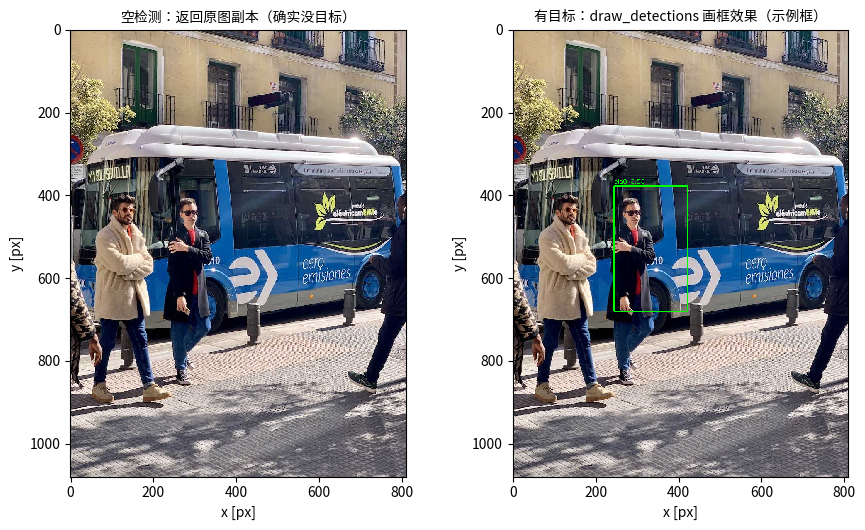

In [4]:
try:
    import numpy as np
    import matplotlib.pyplot as plt

    # 底图优先用仓库里的真实素材（找不到才退化为合成灰图）—— 画框效果才看得出来
    if REAL_IMAGE:
        import cv2
        image = cv2.imread(REAL_IMAGE)
    else:
        image = np.full((240, 320, 3), 100, dtype=np.uint8)
    h, w = image.shape[:2]
    before = image.copy()

    canvas_empty = dn.draw_detections(image, [])
    canvas_box = dn.draw_detections(image, [
        # 示例框：本单元演示的是「画框函数」本身，真实检测结果见 detector.ipynb §3
        DetectedTarget(class_id=0, confidence=0.88,
                       bbox=(w * 0.30, h * 0.35, w * 0.22, h * 0.28)),
    ])
    print("入参未被修改:", bool((image == before).all()))
    print("空检测返回原图副本:", bool((canvas_empty == image).all()))

    fig, axes = plt.subplots(1, 2, figsize=(9, 5.4))
    for ax, im, title in ((axes[0], canvas_empty, "空检测：返回原图副本（确实没目标）"),
                          (axes[1], canvas_box, "有目标：draw_detections 画框效果（示例框）")):
        ax.imshow(im[:, :, ::-1]); ax.set_title(title, fontsize=10)
        ax.set_xlabel("x [px]"); ax.set_ylabel("y [px]")
    plt.tight_layout(); plt.show()
except (ImportError, AttributeError) as exc:
    print("[跳过] 需先 source ROS 并 catkin_make：", exc)


## 3. `image_msg_to_array` —— 编码归一化

ROS 图像的 `encoding` 可能是 `bgr8` / `rgb8` / `mono8`。
统一转成 **3 通道 BGR**，使 `detector.detect()` 不必关心上游编码。

In [5]:
try:
    import numpy as np
    from cv_bridge import CvBridge

    bridge = CvBridge()

    bgr = np.zeros((48, 64, 3), dtype=np.uint8); bgr[:, :, 0] = 200
    msg_bgr = bridge.cv2_to_imgmsg(bgr, encoding="bgr8")
    out = dn.image_msg_to_array(msg_bgr, bridge)
    print("bgr8  ->", out.shape, " B 通道保留在 index 0:", int(out[0, 0, 0]) == 200)

    mono = np.full((30, 40), 128, dtype=np.uint8)
    msg_mono = bridge.cv2_to_imgmsg(mono, encoding="mono8")
    out2 = dn.image_msg_to_array(msg_mono, bridge)
    print("mono8 ->", out2.shape, "（已归一化为 3 通道）")
except ImportError as exc:
    print("[跳过] 需先 source ROS 并 catkin_make：", exc)

bgr8  -> (48, 64, 3)  B 通道保留在 index 0: True
mono8 -> (30, 40, 3) （已归一化为 3 通道）


## 4. 端到端 E2E

真正跑通数据流请用编排脚本（可重复执行、自动清理）：

```bash
bash test/detector/e2e_test/run_e2e.sh                       # 阶段A：链路 + 空也发
IMAGE=/path/to/target.jpg bash test/detector/e2e_test/run_e2e.sh   # 加阶段B：正常检出
```

阶段 A 断言 `/detections` 在流且 `targets` 恒为空；阶段 B 额外校验
**bbox 合法性**（宽高为正、不越界 → 专治 `xyxy`/`xywh` 搞混）。